In [1]:
%load_ext autoreload
%autoreload 2

import os, sys, random, logging

os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0,1,2,3,4")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
sys.path.append("../..")


In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from rich.console import Console
from rich.theme import Theme
from rich.markup import escape

from src.utils import logging_utils

console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

logging_utils.configure(level=logging.INFO)
logger = logging.getLogger(__name__)


In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")


2026-07-08 16:54:42 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models
2026-07-08 16:54:42 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-08 16:54:42 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-07-08 16:54:42 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-08 16:54:42 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-07-08 16:54:42 ht

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-07-08 16:54:54 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-08 16:54:54 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-07-08 16:54:55 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64, n_embd=5120, n_heads=40


In [4]:
# ── loaders for completion-mask results (scripts/clock/train_completion_mask.py) ──
from src.goals.oid_gaze import cache_root
from src.goals.head_loc_attn import HeadMask

COMPLETION_VERSION = "conditions"
# swap to "completion_mask_gaze" if you want the gaze-obj variant instead
MASK_KIND = "completion_mask"
COMPLETION_MASK_ROOT = os.path.join(cache_root(MODEL_NAME, COMPLETION_VERSION), MASK_KIND)


def list_completion_masks():
    if not os.path.isdir(COMPLETION_MASK_ROOT):
        return []
    items = [
        (t, os.path.join(COMPLETION_MASK_ROOT, t),
         os.path.getmtime(os.path.join(COMPLETION_MASK_ROOT, t)))
        for t in os.listdir(COMPLETION_MASK_ROOT)
        if os.path.isdir(os.path.join(COMPLETION_MASK_ROOT, t))
    ]
    return sorted(items, key=lambda x: x[2], reverse=True)


def load_completion_mask(tag=None):
    items = list_completion_masks()
    assert items, f"no {MASK_KIND} results under {COMPLETION_MASK_ROOT}"
    if tag is None:
        d = items[0][1]
    else:
        matches = [it for it in items if tag in it[0]]
        assert matches, f"no run under {COMPLETION_MASK_ROOT} contains tag {tag!r}"
        d = matches[0][1]
    ck = torch.load(os.path.join(d, "mask.pt"), map_location="cpu", weights_only=False)
    ck["dir"] = d
    return ck


def completion_mask_to_headmask(ck):
    layers = [int(x) for x in ck["layers"]]
    nH = ck["mask_values"].shape[1]
    hm = HeadMask(len(layers), nH)
    with torch.no_grad():
        hm.values.copy_(ck["mask_values"])
    return hm

def _tok(i):
    return mt.tokenizer.decode(i)

In [5]:
# ── pick a mask and inspect it ──
# COMPLETION_MASK_TAG = None    # newest by mtime
COMPLETION_MASK_TAG = "lam10.0"   # completion_mask
# COMPLETION_MASK_TAG = "lam100.0"   # completion_mask_gaze

CK     = load_completion_mask(COMPLETION_MASK_TAG)
layers = [int(x) for x in CK["layers"]]
mv     = CK["mask_values"].numpy()
hist   = CK["history"]
meta   = CK["meta"]
sel_heads    = [tuple(int(z) for z in lh) for lh in CK["decision_heads"]]
thr    = float(meta.get("sel_threshold", 0.9))

print(f"[{os.path.basename(CK['dir'])}]")
print(f"  layers {layers[0]}-{layers[-1]} ({len(layers)} masked) · patch_tokens={CK['patch_tokens']} · "
      f"direction={meta['direction']} · same={meta['same']} · N={meta['n_pairs']}")
print(f"  {len(sel_heads)} decision heads (mask>{thr}) · "
      f"final train score={hist['train_score'][-1]:+.4f} · val score={hist['val_score'][-1]:+.4f}")
ranked = sorted(sel_heads, key=lambda lh: mv[layers.index(lh[0]), lh[1]], reverse=True)
print("  top decision heads:", [f"L{l}H{h}" for (l, h) in ranked[:15]])


[diff_pt-2_both_L0-64_lam10.0_n600]
  layers 0-63 (64 masked) · patch_tokens=[-2] · direction=both · same=False · N=600
  251 decision heads (mask>0.5) · final train score=+7.7008 · val score=+7.2003
  top decision heads: ['L13H22', 'L14H25', 'L15H23', 'L20H28', 'L21H0', 'L22H17', 'L22H19', 'L22H29', 'L23H14', 'L25H19', 'L27H16', 'L28H13', 'L28H27', 'L28H29', 'L30H3']


In [6]:
# ── selected heads (mask > thr) as a set + a binary HeadMask for patching ──
SEL_THRESHOLD = 0.8
n_layer_total = mt.model.config.num_hidden_layers
n_heads_total = mv.shape[1]

full_mask = np.full((n_layer_total, n_heads_total), np.nan, dtype=float)
for li, L in enumerate(layers):
    full_mask[L] = mv[li]

sel_set   = {(int(l), int(h)) for l, h in np.argwhere(full_mask > SEL_THRESHOLD)}
sel_heads = sorted(sel_set)

# Default set used for interventions in §3–§5. The separator-analysis cells below overwrite
# this with filtered_sel_heads; seeding it here keeps §3–§5 runnable even if that step is skipped.
DECISION_HEADS = sel_heads

mask_bin = HeadMask(len(layers), n_heads_total)
with torch.no_grad():
    mask_bin.values.zero_()
    for (l, h) in sel_set:
        mask_bin.values[layers.index(l), h] = 1.0
print(f"mask_bin: {int(mask_bin.values.sum().item())} heads = 1.0  (binary @ thr {SEL_THRESHOLD})")
print(f"DECISION_HEADS: {len(DECISION_HEADS)} heads (default = sel_heads; override via the filter cell)")


def get_mask_bin(heads):
    """HeadMask (on CPU) with 1.0 for `heads`, 0.0 elsewhere. Layer index space is `layers`."""
    hm = HeadMask(len(layers), n_heads_total)
    with torch.no_grad():
        hm.values.zero_()
        for (l, h) in heads:
            hm.values[layers.index(l), h] = 1.0
    return hm


mask_bin: 181 heads = 1.0  (binary @ thr 0.8)
DECISION_HEADS: 181 heads (default = sel_heads; override via the filter cell)


In [7]:
# -- selected heads: does OV write at the pivot separate stay (ml) vs move-on (sl)? --
from torch.nn.functional import cosine_similarity as _cos
from src.goals.completion_pairs import build_completion_pairs
from src.goals.head_loc_attn import collect_head_steering_vecs
from src.tokens import prepare_input

N_DECISION = 100
PIVOT_POS = -2

# minimal pairs: source IS dest (same spec, ml vs sl differ only at the target line)
dec_pairs = build_completion_pairs(
    mt, n_pairs=N_DECISION, direction="both", same=True,
    patch_tokens=tuple(int(t) for t in CK["patch_tokens"]), seed=2024,
)
stay_prompts = [p.source.ml_prompt for p in dec_pairs]    # incomplete target  -> stay/continue
move_prompts = [p.source.sl_prompt for p in dec_pairs]    # complete target    -> moved_on
print(f"{len(dec_pairs)} minimal pairs; reading {len(sel_heads)} selected heads at pos {PIVOT_POS}")

# per-head OV write at the pivot for both situations (left-pad => -2 aligns across lengths)
stay_tok = prepare_input(stay_prompts, tokenizer=mt, padding_side="left")
move_tok = prepare_input(move_prompts, tokenizer=mt, padding_side="left")
_, stay_h = collect_head_steering_vecs(mt, stay_tok, sel_heads, [PIVOT_POS], return_individual_heads=True)
_, move_h = collect_head_steering_vecs(mt, move_tok, sel_heads, [PIVOT_POS], return_individual_heads=True)


rows = []
for (l, h) in sorted(sel_heads):
    stay = stay_h[(l, h)][:, 0, :].float()   # (N, n_embd)
    move = move_h[(l, h)][:, 0, :].float()   # (N, n_embd)
    per_pair = _cos(stay, move, dim=1)                       # (N,)  cos within each spec
    mean_vs_mean = _cos(stay.mean(0), move.mean(0), dim=0).item()
    rows.append((l, h, per_pair.mean().item(), per_pair.std().item(), mean_vs_mean))

rows.sort(key=lambda r: r[2])   # most-separating (lowest cosine) first
print(f"\n{'layer':>5} {'head':>5} {'per-pair cos (mean+/-std)':>26} {'mean-vs-mean cos':>18}")
for l, h, m, s, mm in rows:
    print(f"{l:5d} {h:5d} {m:>14.3f} +/-{s:<7.3f} {mm:>18.3f}")

  built 25/100 pairs (27 attempts)
  built 50/100 pairs (54 attempts)
  built 75/100 pairs (79 attempts)
  built 100/100 pairs (104 attempts)
built 100 pairs from 104 attempts
100 minimal pairs; reading 181 selected heads at pos -2

layer  head  per-pair cos (mean+/-std)   mean-vs-mean cos
   51     4          0.006 +/-0.340               -0.070
   44    28          0.120 +/-0.193                0.101
   31    10          0.129 +/-0.205                0.010
   47    31          0.155 +/-0.233                0.595
   13    22          0.174 +/-0.214                0.221
   40    32          0.177 +/-0.222                0.084
   48    26          0.178 +/-0.197                0.266
   14    25          0.179 +/-0.204                0.327
   48    28          0.181 +/-0.210                0.210
   51     2          0.207 +/-0.299                0.307
   28    13          0.228 +/-0.221                0.223
   43    16          0.246 +/-0.196                0.279
   38    29          0.24

In [24]:
filtered_sel_heads = [
    (l, h)
    for (l, h), m, s, mm in zip(
        sel_heads, [r[2] for r in rows], [r[3] for r in rows], [r[4] for r in rows]
    )
    if m < 0.7
]
print(len(filtered_sel_heads), len(sel_heads))


#######################################################################
DECISION_HEADS = filtered_sel_heads
# PATCH_HEADS = sel_heads
#######################################################################
len(DECISION_HEADS)

140 181


140

In [25]:
from src.goals.head_loc_attn import HeadMask
from src.utils import env_utils
import matplotlib.patches as mpatches
from scripts.clock.score_condition_heads import load_head_scores


# ── pick the scoring config to inspect ────────────────────────────────────────
Q_SPAN = 15
COMPARE_WITH = "mean"        # "mean" | "max"
TOP_K = 150
VERSION = "conditions"
# ──────────────────────────────────────────────────────────────────────────────
gaze_scores = load_head_scores(model=MODEL_NAME, version=VERSION, q_span=Q_SPAN, compare_with=COMPARE_WITH)["combined"]

# ── top-K gaze heads ──────────────────────────────────────────────────────────
# flat_idx = np.argsort(gaze_scores, axis=None)[::-1][:TOP_K]
LO_LAYER = 0
head_idx_to_gaze_scores = []
for layer_idx in range(LO_LAYER, gaze_scores.shape[0]):
    for head_idx in range(gaze_scores.shape[1]):
        head_idx_to_gaze_scores.append(((layer_idx, head_idx), gaze_scores[layer_idx, head_idx]))
head_idx_to_gaze_scores = sorted(head_idx_to_gaze_scores, key=lambda x: x[1], reverse=True)[:TOP_K]

gaze_heads = [(l, h) for (l, h), _ in head_idx_to_gaze_scores]
print(f"top-{TOP_K} gaze heads  (compare_with='{COMPARE_WITH}', q_span={Q_SPAN})  "
      f"score range [{gaze_scores[gaze_heads[-1]]:.3f}, {gaze_scores[gaze_heads[0]]:.3f}]")
for rank, (l, h) in enumerate(gaze_heads[:15], start=1):
    print(f"  {rank:2d}. L{l:2d} H{h:2d}  score={gaze_scores[l, h]:.3f}")
if TOP_K > 15:
    print(f"  ... (+ {TOP_K - 15} more)")

top-150 gaze heads  (compare_with='mean', q_span=15)  score range [2.579, 3.478]
   1. L53 H16  score=3.478
   2. L52 H23  score=3.464
   3. L40 H21  score=3.452
   4. L51 H13  score=3.451
   5. L36 H23  score=3.422
   6. L59 H34  score=3.364
   7. L34 H11  score=3.358
   8. L45 H12  score=3.293
   9. L48 H 8  score=3.277
  10. L51 H11  score=3.246
  11. L45 H11  score=3.222
  12. L48 H 5  score=3.217
  13. L50 H12  score=3.181
  14. L32 H23  score=3.175
  15. L53 H18  score=3.168
  ... (+ 135 more)


decision heads: 140  ·  gaze top-150: 150 in masked band
overlap (both): 14  ·  Jaccard within band = 0.051
  overlap heads: ['L25H18', 'L25H19', 'L40H0', 'L42H31', 'L43H29', 'L43H5', 'L44H13', 'L45H20', 'L45H23', 'L45H8', 'L46H29', 'L46H38', 'L46H8', 'L47H8']


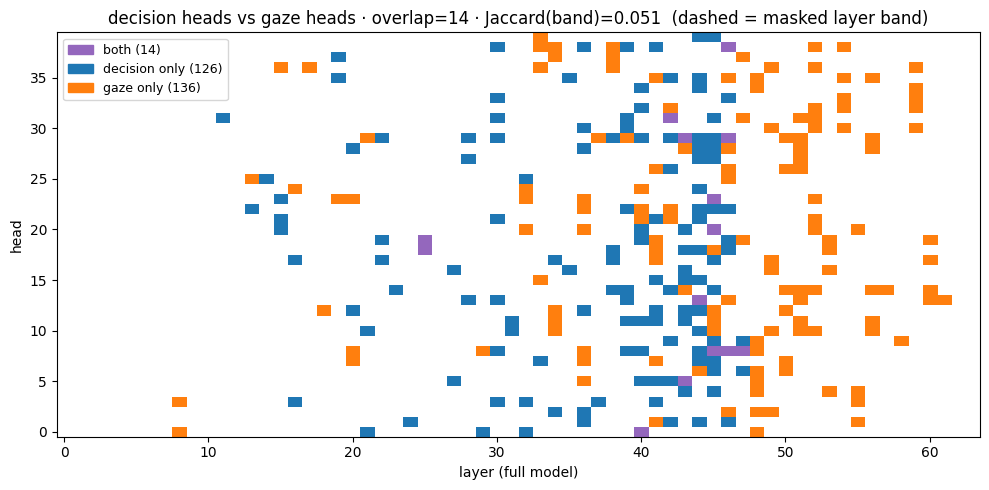

In [26]:
# Plot the gaze heads with DECISION_HEADS overlaid
# needs `gaze_heads` (gaze-score cell) and `DECISION_HEADS` (§1 selection / filter cell).
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

gaze_set  = {(int(l), int(h)) for (l, h) in gaze_heads}
PATCH_SET = set(DECISION_HEADS)
both      = PATCH_SET & gaze_set
mask_only = PATCH_SET - gaze_set
gaze_only = gaze_set - PATCH_SET

# the mask can only select WITHIN its masked layer band — restrict gaze there for a fair
# Jaccard, but plot the full picture.
band = set(layers)
gaze_in_band = {(l, h) for (l, h) in gaze_set if l in band}
jac = len(both) / max(len(PATCH_SET | gaze_in_band), 1)
print(f"decision heads: {len(PATCH_SET)}  ·  gaze top-{len(gaze_set)}: "
      f"{len(gaze_in_band)} in masked band")
print(f"overlap (both): {len(both)}  ·  Jaccard within band = {jac:.3f}")
print("  overlap heads:", sorted(f"L{l}H{h}" for (l, h) in both))

# categorical grid: 0 none · 1 gaze-only · 2 decision-only · 3 both
cat = np.zeros((n_layer_total, n_heads_total))
for (l, h) in gaze_only: cat[l, h] = 1
for (l, h) in mask_only: cat[l, h] = 2
for (l, h) in both:      cat[l, h] = 3
cats_cmap = ListedColormap(["#ffffff", "#ff7f0e", "#1f77b4", "#9467bd"])

fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(cat.T, aspect="auto", cmap=cats_cmap, vmin=0, vmax=3,
          origin="lower", interpolation="nearest")
ax.axvline(layers[0] - 0.5, color="k", ls="--", lw=0.7)
ax.axvline(layers[-1] + 0.5, color="k", ls="--", lw=0.7)
ax.set_xlabel("layer (full model)"); ax.set_ylabel("head")
ax.set_title(f"decision heads vs gaze heads · overlap={len(both)} · "
             f"Jaccard(band)={jac:.3f}  (dashed = masked layer band)")
handles = [mpatches.Patch(color=c, label=lab) for c, lab in [
    ("#9467bd", f"both ({len(both)})"),
    ("#1f77b4", f"decision only ({len(mask_only)})"),
    ("#ff7f0e", f"gaze only ({len(gaze_only)})"),
]]
ax.legend(handles=handles, loc="upper left", fontsize=9)
fig.tight_layout(); plt.show()


## Target Signal `move-on` from (i) end of multiline completion, (ii) end of a chunky segment.

In [27]:
from src.goals.completion_pairs import build_completion_pairs, LEG_STYLES
from src.goals.head_loc_attn import get_o_proj_inputs_batch
from src.tokens import prepare_input

# ── config for the mean signal ──
HP_DIRECTION   = "sl->ml"          # "sl->ml" = MOVE-ON mean (push a stay dest to move on)
                                   # "ml->sl" = STAY    mean (push a move-on dest to stay)
PATCH_POS      = int(CK["patch_tokens"][0]) if len(CK["patch_tokens"]) == 1 else -2
N_MEAN_SRC     = 200
MEAN_SRC_BATCH = 16
MEAN_SEED      = 1234

src_style = "sl" if HP_DIRECTION == "sl->ml" else "ml"
sig_name  = "move-on" if src_style == "sl" else "stay"
print(f"target: mean '{sig_name}' signal ({HP_DIRECTION}) at POS={PATCH_POS} over N={N_MEAN_SRC}")

ss = LEG_STYLES[HP_DIRECTION][
    "src_style"
]  # source donates this style (== dest's target)
ds = LEG_STYLES[HP_DIRECTION]["dst_style"]  # dest runs (clean) this style
PATCH_POS = int(CK["patch_tokens"][0]) if len(CK["patch_tokens"]) == 1 else POS

print(f"{ss=}, {ds=}, {PATCH_POS=}")

target: mean 'move-on' signal (sl->ml) at POS=-2 over N=200
ss='sl', ds='ml', PATCH_POS=-2


In [28]:
# ── one validated (source, dest) transplant pair + cached source heads ─────────
from sys import prefix

from sys import prefix

from src.goals.head_loc_attn import (
    get_o_proj_inputs_batch,
    make_head_replacement_patch_interface,
)
from src.goals.goalscope import headpatched_generate
from src.functional import generate_with_patch
from src.goals.multiline_prompts import (
    build_example,
    replace_in_code_newline_with_tabnewline,
)

assert sel_set, (
    "no heads above SEL_THRESHOLD — lower it in the §6 selection cell or retrain"
)

#####################################################################
NAMING = "letters"  # "letters" | "natural" | "indexed"
N_GEN = 32
#####################################################################

seed = random.Random(1234)
souce_example = build_example(
    mt=mt,
    rng=seed,
    target_slot=3,
    n_conditions=6,
    mode="chat",
    # style="singleline" if ss=="sl" else "multiline",
    style="multiline" if ss == "sl" else "singleline",
    naming=NAMING,
)

src_prompt = souce_example["full_prompt"]

prefix=""
# prefix="    is_even = is_even == 0\n"
# prefix="    d = d == 0\n"
# prefix="    is_palindrome = is_palindrome == is_palindrome[::-1]\n"
prefix="    is_coprime = n != 0 and is_coprime == 1\n"

src_prompt = src_prompt + prefix
src_prompt = replace_in_code_newline_with_tabnewline(src_prompt) + "   "

source_gen = generate_with_patch(
    mt,
    inputs=src_prompt,
    n_gen_per_prompt=1,
    max_new_tokens=N_GEN,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(
    f"[white]{escape(src_prompt)}[/white][medium_orchid1]{escape(source_gen)}[/medium_orchid1]"
)

# cache the SOURCE o_proj inputs at PATCH_POS for the masked layers -> (n_layers, n_embd)
src_cache = get_o_proj_inputs_batch(
    mt, [src_prompt], layers, token_positions=[PATCH_POS]
)
src_o_proj_inps = torch.stack(
    [src_cache[l][0, 0] for l in layers]
)  # (n_layers, n_embd)
print("src_o_proj_inps:", tuple(src_o_proj_inps.shape))

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. the product of n's digits is greater than 0
2. n is a perfect square
3. n is even
4. n is divisible by 4
5. n is a prime number
6. the sum of n's digits is greater than 5

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = 1    
    for d in str(abs(n)):    
        a *= int(d)    
    a = a > 0    
    b = n >= 0 and int(abs(n) ** 0.5) ** 2 == n    
    c = n % 2 == 0    
    d = n % 4    
    is_coprime = n != 0 and is_coprime == 1    
    for i in range(2, int(abs(n) ** 0.5) + 1):    
        if n % i == 0:    

src_o_proj_inps: (64, 5120)


In [29]:
from src.goals.condition_data import (
    sample_specs,
    materialize,
    chunky_predicates_for,
    DATATYPES,
)
import re
from collections import Counter
from src.goals.functional import apply_chat_template, supports_chat_template


# ── config ──
N_SPECS = 1  # specs per datatype
NUM_CONDITIONS = [4]
SEED = 123
MAX_NEW_TOKENS = 256
CHUNKY_DTYPES = list(
    DATATYPES
)  # all 6: int, str, list[int], list[str], list[list[int]], dict[str, int]


# ────────────
def _dt_code(dt):
    return re.sub(r"[^a-z0-9]+", "", dt)  # spec-id-safe tag ("list[int]" -> "listint")

def build_prompt(sample):
    # name_rule="free" (no a/b/c constraint) + multistep nudge -> multi-line implementations
    instr = sample.render_instruction(name_rule="free", multistep=True)
    stub  = sample.render_code_stub()
    if supports_chat_template(mt):
        return apply_chat_template(mt=mt, user_query=instr.strip(), incomplete_code=stub)
    return instr + "\nAnswer:\n" + stub


chunky_samples = []

for dt in CHUNKY_DTYPES:
    dt_specs = sample_specs(
        N_SPECS,
        NUM_CONDITIONS,
        seed=SEED,
        predicates=chunky_predicates_for(dt),
        allow_repeats=False,
    )
    for j, sp in enumerate(dt_specs):
        sp.spec_id = f"chunky_{_dt_code(dt)}_{j:02d}"
    chunky_samples += materialize(
        dt_specs, langs=["python"], modularities=["monolithic"]
    )

print(
    f"{len(chunky_samples)} chunky samples across {len(CHUNKY_DTYPES)} datatypes:",
    dict(Counter(s.spec.datatype for s in chunky_samples)),
)
for s in chunky_samples:
    print(f"  {s.spec.spec_id}  ({s.spec.num_conditions})  {s.spec.predicate_ids}")

6 chunky samples across 6 datatypes: {'int': 1, 'str': 1, 'list[int]': 1, 'list[str]': 1, 'list[list[int]]': 1, 'dict[str, int]': 1}
  chunky_int_00  (4)  ['int_digit_product_gt_chunky', 'int_abundant_chunky', 'int_contains_digit_chunky', 'int_strictly_decreasing_digits_chunky']
  chunky_str_00  (4)  ['str_all_alnum_chunky', 'str_digit_count_ge_chunky', 'str_letter_a_count_ge_chunky', 'str_non_increasing_chunky']
  chunky_listint_00  (4)  ['listint_sum_gt_chunky', 'listint_all_distinct_chunky', 'listint_first_equals_last_chunky', 'listint_has_negative_chunky']
  chunky_liststr_00  (4)  ['liststr_distinct_first_letters_ge_chunky', 'liststr_total_chars_gt_chunky', 'liststr_count_starting_c_ge_chunky', 'liststr_longest_word_gt_chunky']
  chunky_listlistint_00  (4)  ['matrix_every_row_sorted_chunky', 'matrix_contains_zero_chunky', 'matrix_count_zero_ge_chunky', 'matrix_strictly_increasing_diagonal_chunky']
  chunky_dictstrint_00  (4)  ['dict_all_keys_short_chunky', 'dict_max_value_gt_chunk

In [30]:
chunky_sample = next(s for s in chunky_samples if s.spec.datatype == "list[list[int]]")
src_prompt = build_prompt(chunky_sample)

prefix=""
# prefix="""    product = 1
#     for digit in str(n):
#         product *= int(digit)
#     condition1 = product > 10\n"""
# prefix="""    rows_sorted = True
#     for row in grid:
#         for i in range(len(row) - 1):
#             if row[i] > row[i + 1]:
#                 rows_sorted = False
#                 break\n"""
prefix="""    rows_sorted = True    
    for row in grid:    
        for i in range(len(row) - 1):    
            if row[i] > row[i + 1]:    
                rows_sorted = False    
                break    
    contains_zero = False    
    zero_count = 0    
    for row in grid:    
        for element in row:    
            if element == 0:    
                contains_zero = True    
                zero_count += 1    
    at_least_two_zeros = zero_count >= 2\n"""

src_prompt = src_prompt + prefix
src_prompt = replace_in_code_newline_with_tabnewline(src_prompt) + "   "

tokenized = prepare_input(src_prompt, tokenizer=mt, padding_side="left")

orig_gen = generate_with_patch(
    mt,
    inputs=tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=MAX_NEW_TOKENS,
    do_sample=False,
    remove_prefix=True,
)[0]

rich_print(
    f"[bold]chunky str | clean          [/bold] [white]{escape(src_prompt)}[/white][medium_orchid1]{escape(orig_gen)}[/medium_orchid1]"
)

# cache the SOURCE o_proj inputs at PATCH_POS for the masked layers -> (n_layers, n_embd)
src_cache = get_o_proj_inputs_batch(
    mt, [src_prompt], layers, token_positions=[PATCH_POS]
)
src_o_proj_inps = torch.stack(
    [src_cache[l][0, 0] for l in layers]
)  # (n_layers, n_embd)
print("src_o_proj_inps:", tuple(src_o_proj_inps.shape))

chunky str | clean           <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given a square integer matrix grid (a 
list of equal-length integer rows), checks the following conditions:

1. every row of grid is sorted in ascending order
2. grid contains a zero entry
3. grid has at least 2 zero entries
4. the main diagonal of grid is strictly increasing

For each condition, in the order listed, assign the boolean result of the check to its own local variable. After 
all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Implement each condition's check step by step using explicit statements — loops and intermediate variables where 
appropriate — rather than a single one-line expression or comprehension.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(grid: list[list[int]]):    
    rows_sorted = True        
    for row in grid:        
        for i in range(len(row) - 1):        
            if row[i] > row[i + 1]:        
                rows_sorted = False        
                break        
    contains_zero = False        
    zero_count = 0        
    for row in grid:        
        for element in row:        
            if element == 0:        
                contains_zero = True        
                zero_count += 1        
    at_least_two_zeros = zero_count >= 2    
    diagonal_increasing = True        
    for i in range(1, len(grid)):        
        if grid[i][i] <= grid[i - 1][i - 1]:        
            diagonal_increasing = False        
            break        
    print(f"Rows sorted: {rows_sorted}, Contains zero: {contains_zero}, At least two zeros: {at_least_two_zeros}, 
Diagonal increasing: {diagonal_increasing}, All conditions met: {rows_sorted and contains_zero and 
at_least_two_zeros and diagonal_increasing}")
</code>

src_o_proj_inps: (64, 5120)


In [31]:
from src.functional import predict_next_token

dest_example = build_example(
    mt=mt,
    rng=seed,
    target_slot=1,
    n_conditions=4,
    mode="chat",
    style="singleline" if ds=="sl" else "multiline",
    naming=NAMING
)
dest_prompt = replace_in_code_newline_with_tabnewline(dest_example["full_prompt"]) + "   "
dest_tok = prepare_input(dest_prompt, tokenizer=mt, padding_side="left")


clean_gen = generate_with_patch(
    mt,
    inputs=dest_tok,
    n_gen_per_prompt=1,
    max_new_tokens=N_GEN,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(
    f"[bold]clean        [/bold] [white]{escape(dest_prompt)}[/white]"
    f"[sea_green3]{escape(clean_gen)}[/sea_green3]"
)

clean_top_pred = predict_next_token(
    mt = mt,
    inputs = dest_tok,
)
clean_top_pred

clean         <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is divisible by 18
2. n is a triangular number
3. n is a perfect square
4. n is even

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = n % 18    
    a = a == 0    
    b = int((2 * abs(n)) ** 0.5)    
    b = b * (b + 1) // 2 == n    
    c = int(n ** 0.5)    
    c = c

[[PredictedToken(token=' b', prob=1.0, logit=26.5, token_id=293, metadata=None),
  PredictedToken(token=' c', prob=0.0013275146484375, logit=19.875, token_id=272, metadata=None),
  PredictedToken(token=' t', prob=6.580352783203125e-05, logit=16.875, token_id=259, metadata=None),
  PredictedToken(token=' d', prob=3.528594970703125e-05, logit=16.25, token_id=294, metadata=None),
  PredictedToken(token=' s', prob=1.6689300537109375e-05, logit=15.5, token_id=274, metadata=None)]]

In [32]:
# ── clean dest generation  vs  head-patched dest generation ───────────────────
from src.goals.head_loc_attn import forward_with_src_replacement
from src.functional import interpret_logits

# patch the trained heads' OV write at the pivot (PATCH_POS) on the prefill only
# (n_steer_tokens=1) — matches how the mask was trained.
ALPHA = 2.0
patched_gen = headpatched_generate(
    mt,
    dest_inputs=dest_tok,
    src_o_proj_inps=src_o_proj_inps,
    mask=get_mask_bin(DECISION_HEADS),  # binarized selected heads (eval)
    layers=layers,
    max_new_tokens=N_GEN,
    n_steer_tokens=1,
    patch_input_positions=[PATCH_POS],
    alpha=ALPHA
)

rich_print(
    f"[bold]patched {len(DECISION_HEADS)}[/bold] [white]{escape(dest_prompt)}[/white]"
    f"[salmon1]{escape(patched_gen)}[/salmon1]"
)

patched_logits = forward_with_src_replacement(
    mt,
    dest_inputs=dest_tok,
    mask=get_mask_bin(DECISION_HEADS),
    src_head_inps=src_o_proj_inps,
    layers=layers,
    patch_positions=[PATCH_POS],
    alpha=ALPHA,
)
patched_top_pred = interpret_logits(tokenizer=mt, logits=patched_logits)
patched_top_pred

patched 140 <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is divisible by 18
2. n is a triangular number
3. n is a perfect square
4. n is even

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = n % 18    
    a = a == 0    
    b = int((2 * abs(n)) ** 0.5)    
    c = int(n ** 0.5) ** 2 == n    
    d = n % 2 == 0    
    print(f"Div

[PredictedToken(token=' c', prob=0.9568513035774231, logit=23.375, token_id=272, metadata=None),
 PredictedToken(token=' b', prob=0.019858814775943756, logit=19.5, token_id=293, metadata=None),
 PredictedToken(token=' s', prob=0.010629658587276936, logit=18.875, token_id=274, metadata=None),
 PredictedToken(token=' t', prob=0.00304544810205698, logit=17.625, token_id=259, metadata=None),
 PredictedToken(token=' d', prob=0.00237179733812809, logit=17.375, token_id=294, metadata=None)]

## Sufficiency Test: Does the impulse/deicision heads calculate the target signal `move-on` (or `stay`) by themselves? Or, their pooled info is fed to MLPs, which make the final decision?

In [46]:
# ── one validated (source, dest) transplant pair + cached source heads ─────────
from sys import prefix

from sys import prefix

from src.goals.head_loc_attn import (
    get_o_proj_inputs_batch,
    make_head_replacement_patch_interface,
)
from src.goals.goalscope import headpatched_generate
from src.functional import generate_with_patch
from src.goals.multiline_prompts import (
    build_example,
    replace_in_code_newline_with_tabnewline,
)

assert sel_set, (
    "no heads above SEL_THRESHOLD — lower it in the §6 selection cell or retrain"
)

#####################################################################
NAMING = "letters"  # "letters" | "natural" | "indexed"
N_GEN = 32
#####################################################################

seed = random.Random(1123)
souce_example = build_example(
    mt=mt,
    rng=seed,
    target_slot=3,
    n_conditions=6,
    mode="chat",
    style="singleline" if ss=="sl" else "multiline",
    naming=NAMING,
)

src_prompt = souce_example["full_prompt"]
src_prompt = replace_in_code_newline_with_tabnewline(src_prompt) + "   "

PAIR = pairs[15]
src_prompt = PAIR.source.prompt(ss)

source_gen = generate_with_patch(
    mt,
    inputs=src_prompt,
    n_gen_per_prompt=1,
    max_new_tokens=N_GEN,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(
    f"[white]{escape(src_prompt)}[/white][medium_orchid1]{escape(source_gen)}[/medium_orchid1]"
)

# cache the SOURCE o_proj inputs at PATCH_POS for the masked layers -> (n_layers, n_embd)
src_cache = get_o_proj_inputs_batch(
    mt, [src_prompt], layers, token_positions=[PATCH_POS]
)
src_o_proj_inps = torch.stack(
    [src_cache[l][0, 0] for l in layers]
)  # (n_layers, n_embd)
print("src_o_proj_inps:", tuple(src_o_proj_inps.shape))

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n has more than 4 divisors
2. n has more than 3 ones in its binary representation
3. n is a triangular number
4. the sum of n's proper divisors is greater than n
5. n is a perfect square
6. n is coprime with 15

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = sum(1 for d in range(1, abs(n) + 1) if n % d == 0)    
    a = a > 4    
    b = bin(abs(n)).count("1") > 3    
    c = int((2 * abs(n)) ** 0.5)    
    c = n >= 0 and c * (c + 1) // 2 == n    
    d = sum(d for d in range(1, abs(n)) if n % d == 0)    
    d = n > 0 and d > n    
    e = n >= 0 and int(abs(n) ** 0.5) ** 2 == n    
    f = n % 3 != 0 and n % 5 != 0    
    print(f"{a} {b} {c} {d

src_o_proj_inps: (64, 5120)


In [47]:
from src.functional import predict_next_token

dest_example = build_example(
    mt=mt,
    rng=seed,
    target_slot=1,
    n_conditions=4,
    mode="chat",
    style="singleline" if ds=="sl" else "multiline",
    naming=NAMING
)
dest_prompt = replace_in_code_newline_with_tabnewline(dest_example["full_prompt"]) + "   "
dest_prompt = PAIR.dest.prompt(ds)

dest_tok = prepare_input(dest_prompt, tokenizer=mt, padding_side="left")

clean_gen = generate_with_patch(
    mt,
    inputs=dest_tok,
    n_gen_per_prompt=1,
    max_new_tokens=N_GEN,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(
    f"[bold]clean        [/bold] [white]{escape(dest_prompt)}[/white]"
    f"[sea_green3]{escape(clean_gen)}[/sea_green3]"
)

clean_top_pred = predict_next_token(
    mt = mt,
    inputs = dest_tok,
)
clean_top_pred

clean         <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n has at least 2 digits
2. n is a triangular number
3. the sum of n's digits is greater than 15

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = len(str(abs(n)))    
    a = a >= 2    
    b = int((2 * abs(n)) ** 0.5)    
    b = b * (b + 1) // 2 == abs(n)    
    c = sum(int(digit) for digit in str(abs(n

[[PredictedToken(token=' b', prob=1.0, logit=27.5, token_id=293, metadata=None),
  PredictedToken(token=' c', prob=0.00102996826171875, logit=20.625, token_id=272, metadata=None),
  PredictedToken(token=' d', prob=1.6689300537109375e-05, logit=16.5, token_id=294, metadata=None),
  PredictedToken(token=' t', prob=9.47713851928711e-06, logit=15.9375, token_id=259, metadata=None),
  PredictedToken(token=' triangular', prob=4.231929779052734e-06, logit=15.125, token_id=65494, metadata=None)]]

In [48]:
# ── clean dest generation  vs  head-patched dest generation ───────────────────
from src.goals.head_loc_attn import forward_with_src_replacement
from src.functional import interpret_logits

# patch the trained heads' OV write at the pivot (PATCH_POS) on the prefill only
# (n_steer_tokens=1) — matches how the mask was trained.
ALPHA = 2.0
patched_gen = headpatched_generate(
    mt,
    dest_inputs=dest_tok,
    src_o_proj_inps=src_o_proj_inps,
    mask=get_mask_bin(DECISION_HEADS),  # binarized selected heads (eval)
    layers=layers,
    max_new_tokens=N_GEN,
    n_steer_tokens=1,
    patch_input_positions=[PATCH_POS],
    alpha=ALPHA
)

rich_print(
    f"[bold]patched {len(DECISION_HEADS)}[/bold] [white]{escape(dest_prompt)}[/white]"
    f"[salmon1]{escape(patched_gen)}[/salmon1]"
)

patched_logits = forward_with_src_replacement(
    mt,
    dest_inputs=dest_tok,
    mask=get_mask_bin(DECISION_HEADS),
    src_head_inps=src_o_proj_inps,
    layers=layers,
    patch_positions=[PATCH_POS],
    alpha=ALPHA,
)
patched_top_pred = interpret_logits(tokenizer=mt, logits=patched_logits)
patched_top_pred

patched 140 <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n has at least 2 digits
2. n is a triangular number
3. the sum of n's digits is greater than 15

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = len(str(abs(n)))    
    a = a >= 2    
    b = int((2 * abs(n)) ** 0.5)    
    c = sum(int(digit) for digit in str(abs(n))) > 15    
    print(f"Condition 1: {a}, Condition

[PredictedToken(token=' c', prob=0.9756730794906616, logit=25.25, token_id=272, metadata=None),
 PredictedToken(token=' s', prob=0.01787007600069046, logit=21.25, token_id=274, metadata=None),
 PredictedToken(token=' d', prob=0.0035188267938792706, logit=19.625, token_id=294, metadata=None),
 PredictedToken(token=' b', prob=0.0024184519425034523, logit=19.25, token_id=293, metadata=None),
 PredictedToken(token=' t', prob=0.00010625935829011723, logit=16.125, token_id=259, metadata=None)]

In [49]:
# ── Sufficiency (ii): clamp downstream MLP outputs to their CLEAN (dest-run) values
#    while the heads are patched.  Flip survives → MLPs not needed; flip dies → MLPs mediate.
#    Single-forward next-token logits (the pivot decision) — no generation.
from src.functional import PatchSpec, get_hs, interpret_logits

#####################################################################
mlp_restore_pos = [-2]     # [-1] readout | [-2] pivot | [-2, -1] both
RESTORE_LAYERS  = "ALL"        # "ALL" | "DECISION_HEAD" | explicit list, e.g. list(range(40, 50))
# RESTORE_LAYERS = list(range(40, 50))
#####################################################################

decision_layers = sorted({l for (l, _) in DECISION_HEADS})
if RESTORE_LAYERS == "ALL":
    restore_layers = list(layers)              # upstream-of-heads restores are inert no-ops
elif RESTORE_LAYERS == "DECISION_HEAD":
    restore_layers = decision_layers
else:
    restore_layers = list(RESTORE_LAYERS)
mlp_fmt = mt.mlp_module_name_format
print(f"MLP-restore @ pos {mlp_restore_pos} over {len(restore_layers)} layers "
      f"[{restore_layers[0]}..{restore_layers[-1]}]  (heads in layers {decision_layers})")

# cache CLEAN MLP outputs at the restore positions, then wrap them as replace-PatchSpecs
mlp_locs = [(mlp_fmt.format(l), pos) for l in restore_layers for pos in mlp_restore_pos]
clean_mlp = get_hs(mt, dest_tok, mlp_locs, return_dict=True)
mlp_patches = [
    PatchSpec(location=loc, patch=clean_mlp[loc], strategy="replace", on_pass="first")
    for loc in mlp_locs
]

def _fwd(mask, extra=None):
    return forward_with_src_replacement(
        mt, dest_inputs=dest_tok, src_head_inps=src_o_proj_inps,
        mask=mask, layers=layers, patch_positions=[PATCH_POS], alpha=ALPHA,
        extra_patches=extra,
    )

clean_logits     = _fwd(get_mask_bin([]))                          # no head patch = clean
heads_logits     = _fwd(get_mask_bin(DECISION_HEADS))              # (i) heads-only
heads_mlp_logits = _fwd(get_mask_bin(DECISION_HEADS), mlp_patches) # (ii) heads + MLP-clamp

rich_print(f"[grey62]clean             [/grey62] \n{interpret_logits(mt, clean_logits)}")
rich_print(f"[sea_green3]heads-only        [/sea_green3] \n{interpret_logits(mt, heads_logits)}")
rich_print(f"[salmon1]heads + MLP-clamp [/salmon1] \n{interpret_logits(mt, heads_mlp_logits)}")


clean_tok = mt.tokenizer(" " + dest_example["target_var"], skip_special_tokens=True).input_ids[0]
target_tok = mt.tokenizer(" " + chr(ord(dest_example["target_var"])+1), skip_special_tokens=True).input_ids[0] #! only for `move-on` or "sl->ml". fix it
print(_tok(clean_tok), _tok(target_tok))

METRIC = "logit"
_, clean_track = interpret_logits(mt, clean_logits, interested_tokens=[clean_tok, target_tok])
gold_score = getattr(clean_track[clean_tok][1], METRIC) # <- score(clean_ans | clean_run)
base_score = getattr(clean_track[target_tok][1], METRIC) # <- score(flip_ans | clean_run)

_, head_patch_track = interpret_logits(mt, heads_logits, interested_tokens=[clean_tok, target_tok])
head_score = getattr(head_patch_track[target_tok][1], METRIC) # <- score(clean_ans | heads_run)
head_ie = (head_score - base_score) / (gold_score - base_score)

_, heads_mlp_track = interpret_logits(mt, heads_mlp_logits, interested_tokens=[clean_tok, target_tok])
heads_mlp_score = getattr(heads_mlp_track[target_tok][1], METRIC) # <- score(clean_ans | heads+mlp_run)
heads_mlp_ie = (heads_mlp_score - base_score) / (gold_score - base_score)
print(f"IE(heads-only) = {head_ie:.3f}  ·  IE(heads+MLP-clamp) = {heads_mlp_ie:.3f}")

MLP-restore @ pos [-2] over 64 layers [0..63]  (heads in layers [11, 13, 14, 15, 16, 19, 20, 21, 22, 23, 24, 25, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47])


clean              
[PredictedToken(token=' b', prob=0.998916745185852, logit=27.5, token_id=293, metadata=None), 
PredictedToken(token=' c', prob=0.0010321782901883125, logit=20.625, token_id=272, metadata=None), 
PredictedToken(token=' d', prob=1.668360891926568e-05, logit=16.5, token_id=294, metadata=None), 
PredictedToken(token=' t', prob=9.506033165962435e-06, logit=15.9375, token_id=259, metadata=None), 
PredictedToken(token=' triangular', prob=4.21827689933707e-06, logit=15.125, token_id=65494, metadata=None)]

heads-only         
[PredictedToken(token=' c', prob=0.9756730794906616, logit=25.25, token_id=272, metadata=None), 
PredictedToken(token=' s', prob=0.01787007600069046, logit=21.25, token_id=274, metadata=None), 
PredictedToken(token=' d', prob=0.0035188267938792706, logit=19.625, token_id=294, metadata=None), 
PredictedToken(token=' b', prob=0.0024184519425034523, logit=19.25, token_id=293, metadata=None), 
PredictedToken(token=' t', prob=0.00010625935829011723, logit=16.125, token_id=259, metadata=None)]

heads + MLP-clamp  
[PredictedToken(token=' b', prob=0.9705858826637268, logit=26.125, token_id=293, metadata=None), 
PredictedToken(token=' c', prob=0.02930915541946888, logit=22.625, token_id=272, metadata=None), 
PredictedToken(token=' d', prob=5.6579978263471276e-05, logit=16.375, token_id=294, metadata=None), 
PredictedToken(token=' s', prob=9.832125215325505e-06, logit=14.625, token_id=274, metadata=None), 
PredictedToken(token=' t', prob=8.676820471009705e-06, logit=14.5, token_id=259, metadata=None)]

 b  c
IE(heads-only) = 0.673  ·  IE(heads+MLP-clamp) = 0.291


In [51]:
def get_window(idx, window_size, n_layer):
    return [
        i
        for i in range(
            max(0, idx - window_size // 2), min(n_layer - 1, idx + window_size // 2) + 1
        )
    ]


WINDOW_SIZE = 9
METRIC = "prob"

clean_logits = _fwd(get_mask_bin([]))  # no head patch = clean
heads_logits = _fwd(get_mask_bin(DECISION_HEADS))  # (i) heads-only

_, clean_track = interpret_logits(mt, clean_logits, interested_tokens=[clean_tok, target_tok])
gold_score = getattr(clean_track[clean_tok][1], METRIC) # <- score(clean_ans | clean_run)
base_score = getattr(clean_track[target_tok][1], METRIC) # <- score(flip_ans | clean_run)

_, head_patch_track = interpret_logits(mt, heads_logits, interested_tokens=[clean_tok, target_tok])
head_score = getattr(head_patch_track[target_tok][1], METRIC) # <- score(clean_ans | heads_run)
head_ie = (head_score - base_score) / (gold_score - base_score)
print(f"IE(heads-only) = {head_ie:.3f}")

for layer_idx in range(0, mt.n_layer, 4):
    restore_layers = get_window(layer_idx, WINDOW_SIZE, mt.n_layer)
    mlp_locs = [(mt.mlp_module_name_format.format(l), pos) for l in restore_layers for pos in mlp_restore_pos]
    mlp_patches = [
        PatchSpec(location=loc, patch=clean_mlp[loc], strategy="replace", on_pass="first")
        for loc in mlp_locs
    ]
    heads_mlp_logits = _fwd(get_mask_bin(DECISION_HEADS), mlp_patches) # (ii) heads + MLP-clamp
    _, heads_mlp_track = interpret_logits(mt, heads_mlp_logits, interested_tokens=[clean_tok, target_tok])
    heads_mlp_score = getattr(heads_mlp_track[target_tok][1], METRIC) # <- score(clean_ans | heads+mlp_run)
    heads_mlp_ie = (heads_mlp_score - base_score) / (gold_score - base_score)
    print(f"Layer {layer_idx}: IE(heads+MLP-clamp) = {heads_mlp_ie:.3f}")

IE(heads-only) = 0.977
Layer 0: IE(heads+MLP-clamp) = 0.977
Layer 4: IE(heads+MLP-clamp) = 0.977
Layer 8: IE(heads+MLP-clamp) = 0.979
Layer 12: IE(heads+MLP-clamp) = 0.981
Layer 16: IE(heads+MLP-clamp) = 0.983
Layer 20: IE(heads+MLP-clamp) = 0.978
Layer 24: IE(heads+MLP-clamp) = 0.979
Layer 28: IE(heads+MLP-clamp) = 0.976
Layer 32: IE(heads+MLP-clamp) = 0.982
Layer 36: IE(heads+MLP-clamp) = 0.939
Layer 40: IE(heads+MLP-clamp) = 0.981
Layer 44: IE(heads+MLP-clamp) = 0.059
Layer 48: IE(heads+MLP-clamp) = 0.348
Layer 52: IE(heads+MLP-clamp) = 0.976
Layer 56: IE(heads+MLP-clamp) = 0.942
Layer 60: IE(heads+MLP-clamp) = 0.957


### Scale-up: layer-window MLP-clamp sweep over N pairs

Repeat the windowed MLP-clamp sweep over `N_PAIRS` independent (source, dest) pairs and aggregate the normalized indirect effect (IE) per window center. A dip below the heads-only line = those MLPs mediate the move-on / stay decision.

In [54]:
# ── scale-up: sweep the MLP-clamp window over N_PAIRS validated pairs, collect normalized IE ──
# Pairs come from the SAME machinery the mask trains on (build_completion_pairs): target_slot and
# n_conditions are varied + gated per side, and it hands back the correct clean (dst_ans) and
# counterfactual (target_ans) tokens directly — no letter-arithmetic hack, works for either leg.
import numpy as np, torch
from tqdm.auto import tqdm
from src.goals.completion_pairs import build_completion_pairs

#####################################################################
N_PAIRS          = 100            # validated (source, dest) pairs
SWEEP_STRIDE     = 4             # window-center step (uses WINDOW_SIZE, mlp_restore_pos from above)
TARGET_SLOTS     = (1, 2, 3, 4)  # slots sampled for each side
MAX_CONDITIONS   = 6
MATCH_TARGET_SLOT = False        # True → dest reuses source's slot
MATCH_N_COND      = False        # True → dest reuses source's n_conditions
MIN_HEAD_IE      = 0.2           # skip pairs where the head-only intervention barely works
PAIR_SEED        = 0
#####################################################################

LEG = f"{ss}->{ds}"              # sl->ml or ml->sl, matching the configured HP_DIRECTION
sweep_centers = list(range(0, mt.n_layer, SWEEP_STRIDE))
_mlp_name = mt.mlp_module_name_format.format

pairs = build_completion_pairs(
    mt, n_pairs=N_PAIRS, target_slots=TARGET_SLOTS, direction=LEG, same=False,
    match_target_slot=MATCH_TARGET_SLOT, match_n_cond=MATCH_N_COND,
    max_conditions=MAX_CONDITIONS, mode="chat", seed=PAIR_SEED, patch_tokens=(PATCH_POS,),
)

def _sweep_pair(src_o, dst_tok, clean_tok, target_tok):
    """Return (head_ie, ie_over_centers, valid). clean_tok = dst's clean argmax,
    target_tok = dst's counterfactual (flip) token — both from build_completion_pairs."""
    def _f(mask, extra=None):
        return forward_with_src_replacement(
            mt, dest_inputs=dst_tok, src_head_inps=src_o, mask=mask, layers=layers,
            patch_positions=[PATCH_POS], alpha=ALPHA, extra_patches=extra)

    clean_logits = _f(get_mask_bin([]))
    _, ct = interpret_logits(mt, clean_logits, interested_tokens=[clean_tok, target_tok])
    gold = getattr(ct[clean_tok][1], METRIC)      # score(clean_ans | clean_run)
    base = getattr(ct[target_tok][1], METRIC)     # score(flip_ans  | clean_run)
    denom = gold - base
    if not np.isfinite(denom) or abs(denom) < 1e-3:
        return None, None, False

    heads_logits = _f(get_mask_bin(DECISION_HEADS))
    _, ht = interpret_logits(mt, heads_logits, interested_tokens=[clean_tok, target_tok])
    head_ie = (getattr(ht[target_tok][1], METRIC) - base) / denom
    if head_ie < MIN_HEAD_IE:
        return head_ie, None, False

    # clean MLP cache over ALL layers (windows can exceed the head-patch `layers`)
    all_locs = [(_mlp_name(l), pos) for l in range(mt.n_layer) for pos in mlp_restore_pos]
    cmlp = get_hs(mt, dst_tok, all_locs, return_dict=True)

    ies = []
    for c in sweep_centers:
        patches = [
            PatchSpec(location=(_mlp_name(l), pos), patch=cmlp[(_mlp_name(l), pos)],
                      strategy="replace", on_pass="first")
            for l in get_window(c, WINDOW_SIZE, mt.n_layer) for pos in mlp_restore_pos
        ]
        lg = _f(get_mask_bin(DECISION_HEADS), patches)
        _, tt = interpret_logits(mt, lg, interested_tokens=[clean_tok, target_tok])
        ies.append((getattr(tt[target_tok][1], METRIC) - base) / denom)
    return head_ie, np.array(ies), True

sweep_ies, head_ies = [], []
for pair in tqdm(pairs, desc="pairs"):
    src_prompt = pair.source.prompt(ss)        # source donates head activations (src style)
    dst_prompt = pair.dest.prompt(ds)          # dest is patched + read out (clean style)
    clean_tok  = pair.dest.ans(ds)             # clean answer
    target_tok = pair.dest.ans(ss)             # counterfactual (target_style == src_style)

    src_cache = get_o_proj_inputs_batch(mt, [src_prompt], layers, token_positions=[PATCH_POS])
    src_o = torch.stack([src_cache[l][0, 0] for l in layers])           # (n_layers, n_embd)
    dst_tok = prepare_input(dst_prompt, tokenizer=mt, padding_side="left")

    head_ie, ies, ok = _sweep_pair(src_o, dst_tok, clean_tok, target_tok)
    if ok:
        sweep_ies.append(ies); head_ies.append(head_ie)

sweep_ies = np.stack(sweep_ies) if sweep_ies else np.empty((0, len(sweep_centers)))
head_ies  = np.array(head_ies)
print(f"kept {len(head_ies)}/{len(pairs)} valid pairs  |  heads-only IE = "
      f"{head_ies.mean():.3f} ± {head_ies.std():.3f}" if len(head_ies) else "no valid pairs")


  built 25/100 pairs (37 attempts)
  built 50/100 pairs (65 attempts)
  built 75/100 pairs (102 attempts)
  built 100/100 pairs (136 attempts)
built 100 pairs from 136 attempts


pairs:   0%|          | 0/100 [00:00<?, ?it/s]

kept 96/100 valid pairs  |  heads-only IE = 1.164 ± 1.133


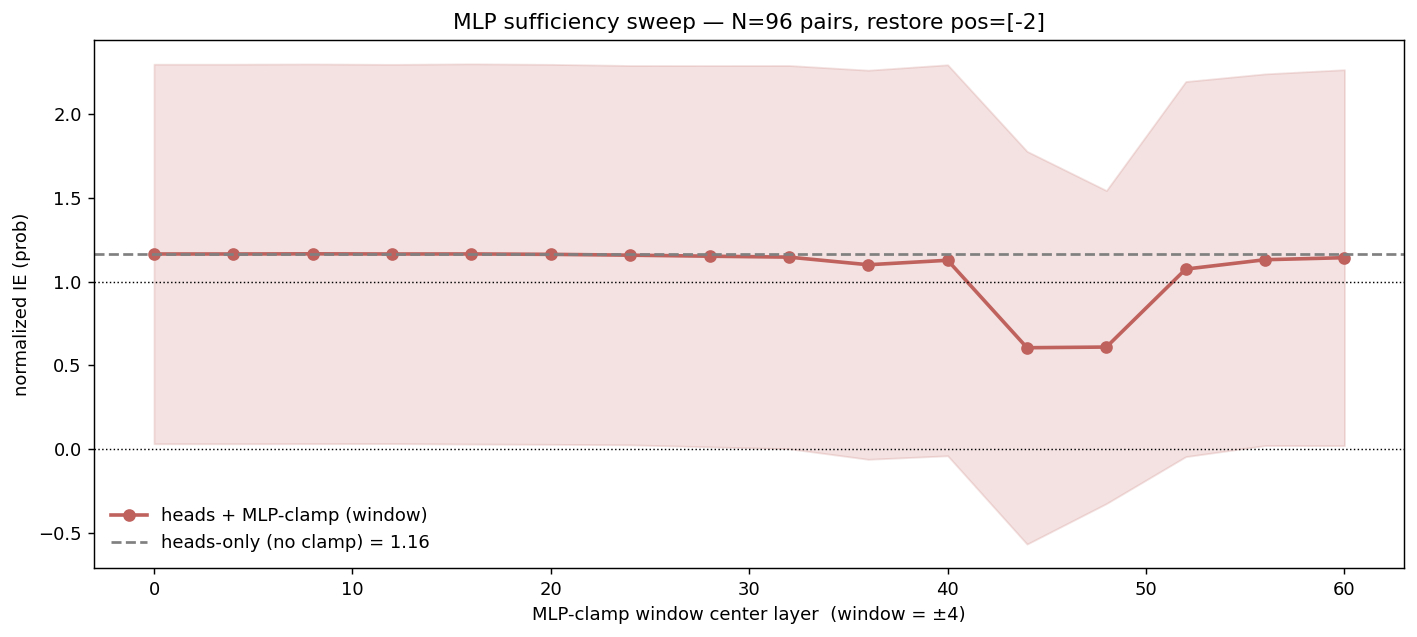

In [55]:
# ── aggregate + plot: mean IE per window center with ±std band ──
import numpy as np
import matplotlib.pyplot as plt

assert len(sweep_ies), "no valid pairs collected — lower MIN_HEAD_IE or increase N_PAIRS"
mean, std = sweep_ies.mean(0), sweep_ies.std(0)
head_mean = head_ies.mean()

fig, ax = plt.subplots(figsize=(11, 5), dpi=130)
ax.plot(sweep_centers, mean, "-o", color="#BF625E", lw=2, label="heads + MLP-clamp (window)")
ax.fill_between(sweep_centers, mean - std, mean + std, color="#BF625E", alpha=0.18)
ax.axhline(head_mean, ls="--", color="grey", lw=1.5, label=f"heads-only (no clamp) = {head_mean:.2f}")
ax.axhline(1.0, ls=":", color="k", lw=0.8)
ax.axhline(0.0, ls=":", color="k", lw=0.8)
ax.set_xlabel(f"MLP-clamp window center layer  (window = ±{WINDOW_SIZE // 2})")
ax.set_ylabel(f"normalized IE ({METRIC})")
ax.set_title(f"MLP sufficiency sweep — N={len(head_ies)} pairs, restore pos={mlp_restore_pos}")
ax.legend(loc="best", frameon=False)
plt.tight_layout(); plt.show()


## Goalscope: Test if the verbalization setup works at the begining of specified todos.

In [56]:
import os
import torch
from src.goals.head_loc_attn import HeadMask

MASK_PATH = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    f"localization/{MODEL_NAME.split('/')[-1]}/head_mask.pt",
)

ckpt = torch.load(MASK_PATH, map_location="cpu")
print(f"Loaded checkpoint from {MASK_PATH}")
# print(f"  Trained for {ckpt['config']['n_epochs']} epochs  |  N={ckpt['config']['n_instances']} instances")
# print(f"  λ_sparse={ckpt['config']['lambda_sparse']}  lr={ckpt['config']['lr']}")

# Reconstruct mask object
LAYERS = ckpt["layers"]
n_layers_tested = len(LAYERS)
n_heads = ckpt["mask_values"].shape[1]
mask = HeadMask(n_layers_tested, n_heads)
with torch.no_grad():
    mask.values.copy_(ckpt["mask_values"])
    if mt.name.split("/")[-1] == "Qwen2.5-Coder-32B-Instruct":
        mask.values[0:25] = 0  # zero out early layers
        mask.values[56:] = 0  # zero out late layers
    if mt.name.split("/")[-1] == "Llama-3.3-70B-Instruct":
        mask.values[0:18] = 0  # zero out early layers
        mask.values[45:] = 0  # zero out late layers

threshold = 0.9
goal_heads = mask.selected_heads(LAYERS, threshold=threshold)
print(
    f"\n  Layers: {LAYERS[0]}–{LAYERS[-1]}  ({n_layers_tested} tested, {n_heads} heads each)"
)
print(f"  Active heads (mask > {threshold}): {len(goal_heads)}")
print(f"  Selected heads: {goal_heads}")

Loaded checkpoint from /disk/u/arnab/Codes/Projects/goals/results/localization/Qwen2.5-Coder-32B-Instruct/head_mask.pt

  Layers: 0–63  (64 tested, 40 heads each)
  Active heads (mask > 0.9): 122
  Selected heads: [(28, 13), (29, 17), (29, 18), (30, 8), (30, 25), (30, 35), (31, 18), (31, 32), (32, 3), (32, 13), (34, 25), (34, 30), (34, 33), (35, 13), (35, 39), (37, 13), (37, 15), (38, 0), (38, 2), (39, 4), (39, 8), (39, 9), (39, 14), (39, 31), (39, 32), (39, 34), (40, 2), (40, 8), (40, 11), (40, 14), (40, 32), (40, 34), (41, 6), (41, 9), (41, 12), (41, 13), (42, 39), (43, 5), (43, 8), (43, 13), (43, 30), (44, 12), (44, 13), (44, 14), (44, 18), (44, 38), (45, 15), (45, 17), (45, 18), (45, 21), (45, 22), (45, 31), (45, 32), (45, 33), (45, 34), (46, 1), (46, 4), (46, 7), (46, 8), (46, 9), (46, 18), (46, 19), (46, 20), (46, 25), (46, 26), (46, 35), (47, 5), (47, 6), (47, 7), (47, 8), (47, 18), (47, 19), (47, 23), (47, 30), (47, 32), (47, 35), (47, 39), (48, 25), (48, 26), (48, 28), (48, 29

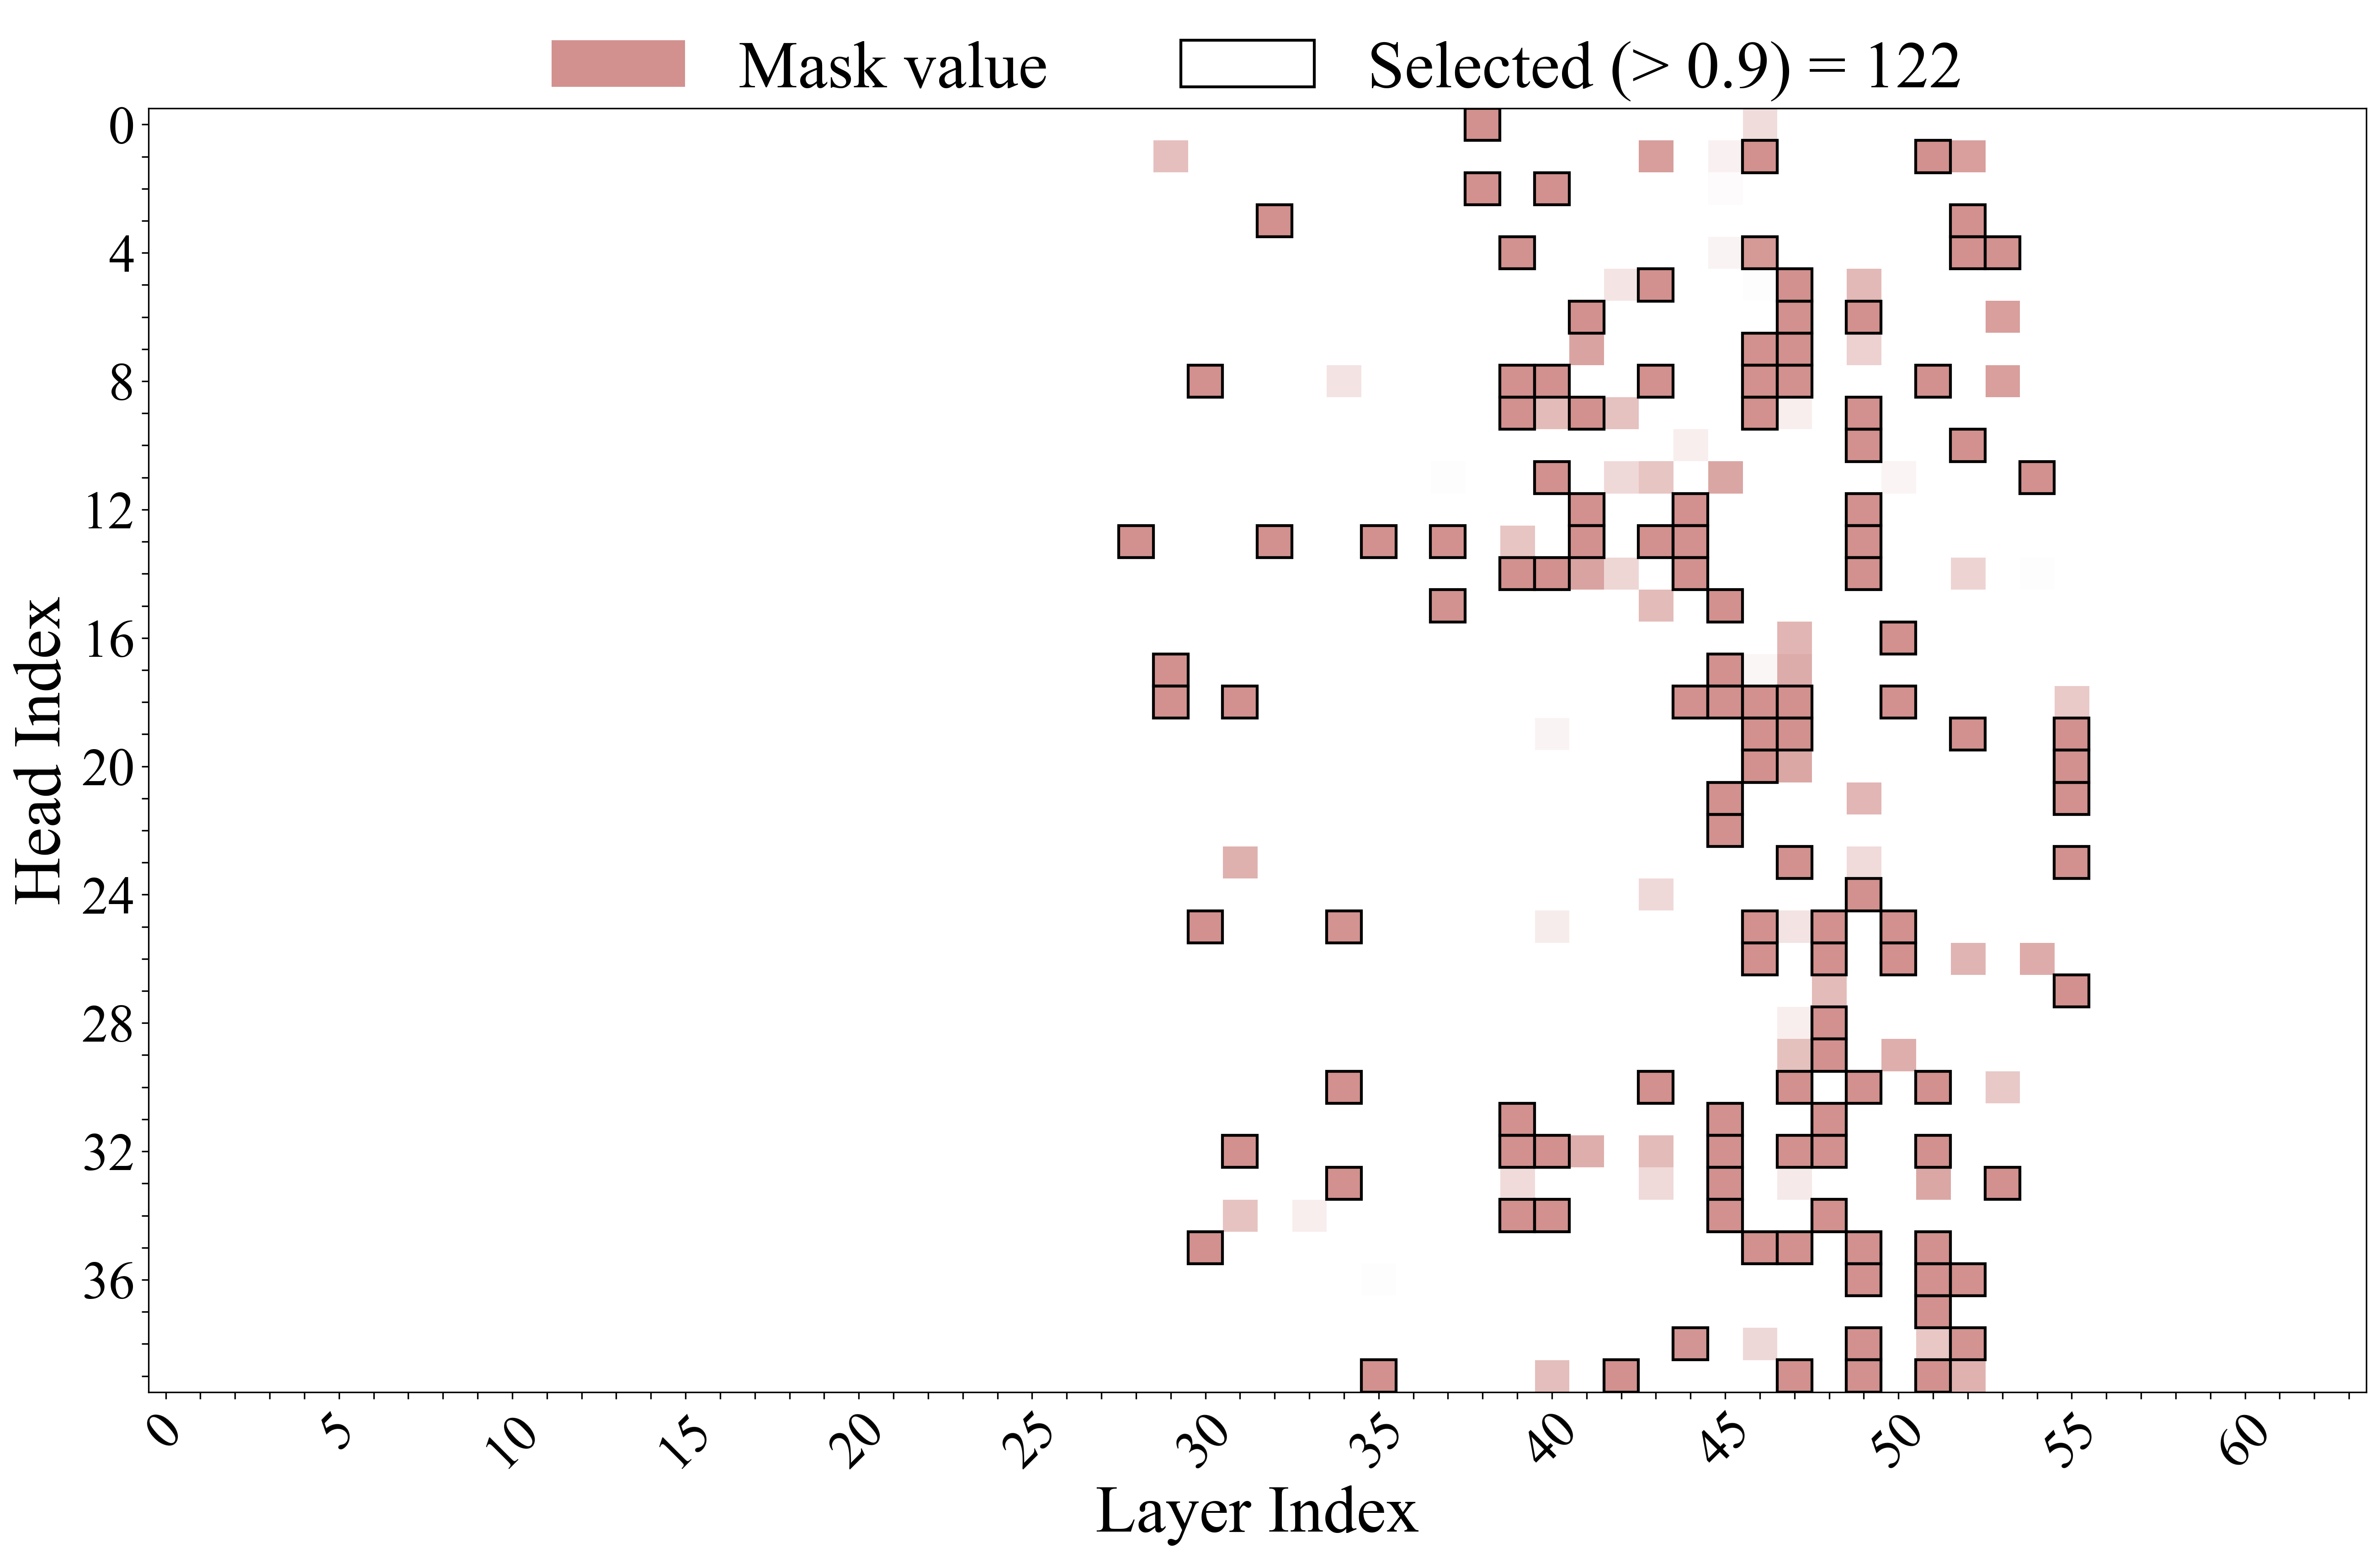

In [57]:
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import pyplot as plt
from matplotlib import patches

plt.rcParams["figure.dpi"] = 300
plt.rcParams["font.family"] = "Times New Roman"

SMALL_SIZE = 28
MEDIUM_SIZE = 35
BIGGER_SIZE = 40

plt.rc("font", size=SMALL_SIZE)
plt.rc("axes", titlesize=BIGGER_SIZE)
plt.rc("axes", labelsize=MEDIUM_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)
plt.rc("legend", fontsize=SMALL_SIZE)
plt.rc("figure", titlesize=BIGGER_SIZE)


def get_ticks(ticks, skip=5, offset=0):
    ret = []
    for i in ticks:
        actual_layer = i + offset
        if actual_layer % skip == 0:
            ret.append(str(actual_layer))
        else:
            ret.append("")
    return ret


_n_heads = mt.config.num_attention_heads
_n_layer = mt.n_layer

# Build continuous mask matrix: shape (n_heads, n_layer)
# Layers outside the optimized range stay 0.
function_mask = torch.zeros((_n_heads, _n_layer), dtype=torch.float32)
for i, layer_idx in enumerate(LAYERS):
    function_mask[:, layer_idx] = mask.values[i].detach().cpu()

# Create figure and axis
fig, ax = plt.subplots(figsize=(18, 12))

colors = ["white", "#BF625E"]
cmap = LinearSegmentedColormap.from_list("white_orange", colors, N=100)

ax.imshow(
    function_mask.numpy(),
    cmap=cmap,
    aspect="auto",
    vmin=0,
    vmax=1,
    alpha=0.7,
)

# Black border around selected heads (mask value > 0.5)
for layer_idx, head_idx in goal_heads:
    rect = patches.Rectangle(
        (layer_idx - 0.5, head_idx - 0.5),
        1,
        1,
        linewidth=1.5,
        edgecolor="black",
        facecolor="none",
    )
    ax.add_patch(rect)

plt.xlabel("Layer Index")
plt.ylabel("Head Index")
plt.xticks(
    ticks=range(_n_layer),
    labels=get_ticks(range(_n_layer)),
    rotation=45,
)
plt.yticks(
    ticks=range(_n_heads),
    labels=get_ticks(range(_n_heads), skip=4),
)

legend_elements = [
    mpatches.Patch(facecolor="#BF625E", alpha=0.7, label="Mask value"),
    mpatches.Patch(
        facecolor="white",
        edgecolor="black",
        linewidth=1.5,
        label=f"Selected (> {threshold}) = {len(goal_heads)}",
    ),
]
ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.1),
    ncol=2,
    fontsize=MEDIUM_SIZE,
    frameon=False,
)

plt.tight_layout()
plt.show()


In [65]:
import torch


from src.goals.head_loc_attn import (
    HeadMask,
    forward_with_src_replacement,
    get_o_proj_inputs_batch,
)
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt
from src.goals.goalscope import greedy_continue
from src.tokens import prepare_input
from src.trace import get_score

# ── Binary mask: 1.0 at selected heads, 0.0 everywhere else ─────────────────
_n_lt = len(LAYERS)
_n_h = mt.config.num_attention_heads
goal_mask = get_mask_bin(goal_heads)

print(
    f"Binary mask: {goal_mask.n_active()} active heads / {_n_lt * _n_h} total heads "
    f"({100 * goal_mask.n_active() / (_n_lt * _n_h):.2f}%)"
)

METRIC = "logit"  # "logit" or "prob"
MAX_NEW_TOKENS = 64
PATCH_ALL_TOKENS = True  # True → patch every generated token

_STOP_IDS = {mt.tokenizer.eos_token_id}


Binary mask: 122 active heads / 2560 total heads (4.77%)


In [68]:
dest_example = build_example(
    mt=mt,
    rng=random.Random(1234),
    target_slot=1,
    n_conditions=4,
    mode="chat",
    style="singleline" if ds=="sl" else "multiline",
    naming="letters"
)
dest_prompt = replace_in_code_newline_with_tabnewline(dest_example["full_prompt"]) + "   "

# chunky_sample = next(s for s in chunky_samples if s.spec.datatype == "str")
# dest_prompt = build_prompt(chunky_sample)

dest_tok = prepare_input(dest_prompt, tokenizer=mt, padding_side="left")

clean_gen = generate_with_patch(
    mt,
    inputs=dest_tok,
    n_gen_per_prompt=1,
    max_new_tokens=256,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(
    f"[bold]clean        [/bold] [white]{escape(dest_prompt)}[/white]"
    f"[sea_green3]{escape(clean_gen)}[/sea_green3]"
)

clean         <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. the product of n's digits is greater than 0
2. n is a perfect square
3. n is even
4. n is divisible by 4

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = 1    
    for d in str(abs(n)):    
        a *= int(d)    
    a = a > 0    
    b = int(abs(n) ** 0.5)    
    b = b * b == abs(n)    
    c = n % 2 == 0    
    d = n % 4 == 0    
    print(f"Condition 1: {a}, Condition 2: {b}, Condition 3: {c}, Condition 4: {d}, All Conditions: {a and b and c 
and d}")
</code>

In [69]:
from src.goals.goalscope import apply_goalscope

goalscope_results = apply_goalscope(
    prompt=dest_prompt + clean_gen,
    mt=mt,
    selected_heads=goal_heads,
    strategy="additive",
    steer_layer_range=(35, 46),
    alpha=0.2,
    max_new_tokens=64,
    n_steer_tokens="all",
    title="GoalScope",
    show=True,
    include_noncode=True,
    goalscope_prompt=None,
    save_path="letters.html"
)

GoalScope[additive]:   0%|          | 0/9 [00:00<?, ?it/s]

Saved -> letters.html
